# Proyecto 1 Trimestre - Programación Inteligencia Artificial - Daniel Nieto Bouza

El objetivo es conocer las carecteristicas de los clientes e investigar que variables  estan asociadas a la baja de la compañia, ademas entrenaremos varios modelos para ver como predicen y si lo hacen bien que clientes se dan de baja y cuales no, tambien veremos metricas mas avanzadas para ver que modelo es el mejor y por ultimo mdificaremos hiperparametros de los modelos para ver si mejoran o empeoran 

### Importamos las liberiar necesarias para el proyecto y cargamos el dataset en una variable
Despues se mostrarán las primeras filas

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

clientes = pd.read_csv("./dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv")
clientes.head(5)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Dimensiones, estructura y tipos de variables del dataset
Vamos a mostra el numero de filas, columas y la información general del dataset

In [38]:
print(f"Numero de filas: {clientes.shape[0]}")
print(f"Numero de columnas: {clientes.shape[1]}")
print("\n Informacion de los datos:")
clientes.info()

Numero de filas: 7043
Numero de columnas: 21

 Informacion de los datos:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-

In [39]:
clientes.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


## Mapear las variables

Este dataset tiene variables categorias que sus valores estan representenado por texto. Para poder utilizar estas variables en los modelos que vamos a implementar despues hay que transformalas a formato numerico.

He utilizado 2 metodos porque nose puedn codificar todas las categorias iguales:

**1. Cofificacion binaria**
En las variables que tienen 2 categorias voy a poner el valor 0 para el No y el 1 para el Yes. Estas variables son: 
**PhoneService, PaperlessBilling, Partner y Dependents** 

**Gender:** 0 para Femenino y 1 para Masculino.

**Y la variable objeto Churn:** En este caso 0 es que el cliente permanece en la empresa y 1 que no permanece

**2. Codificacion con One-hot Encoding**

Voy a utilizarlo en variables que tengan mas de 2 categorias. Este metodo vcrea una nueva columna para cada categoría, asignando un 1 cuando el registro pertenece a ella y un 0 cuando no.

In [40]:
# Creo una copia del dataset para trabajar con ella y no modificar el original
clientes_copia = clientes.copy()

### Codificacion de las variables binarias

In [41]:
variables_binarias = ["PhoneService", "PaperlessBilling", "Partner", "Dependents"]

for variable in variables_binarias:
    clientes_copia[variable] = clientes_copia[variable].map(
        {"Yes": 1,
         "No": 0
        })


clientes_copia["gender"] = clientes_copia["gender"].map(
    {"Male": 1,
     "Female": 0
    })

clientes_copia["Churn"] = clientes_copia["Churn"].map(
    {"Yes": 1, 
     "No": 0
    })

### Codificacion con One-Hot Encoding

In [75]:
variables_categoricas = ["MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaymentMethod"]

clientes_copia = pd.get_dummies(
    clientes_copia,
    columns=variables_categoricas,
    drop_first=False,
    dtype=int
)

KeyError: "['MultipleLines', 'InternetService', 'OnlineSecurity', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod'] not in index"

### Vamos a eliminar de esta copia el costumerID ya que no aporta ninguna informacion al dataset

In [43]:
clientes_copia = clientes_copia.drop(columns=["customerID"])

In [44]:
clientes_copia

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,OnlineBackup,PaperlessBilling,MonthlyCharges,TotalCharges,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,Yes,1,29.85,29.85,...,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,No,0,56.95,1889.5,...,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,Yes,1,53.85,108.15,...,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,No,0,42.30,1840.75,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,No,1,70.70,151.65,...,1,0,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,24,1,No,1,84.80,1990.5,...,0,0,1,0,1,0,0,0,0,1
7039,0,0,1,1,72,1,Yes,1,103.20,7362.9,...,0,0,1,0,1,0,0,1,0,0
7040,0,0,1,1,11,0,No,1,29.60,346.45,...,1,0,0,1,0,0,0,0,1,0
7041,1,1,1,0,4,1,No,1,74.40,306.6,...,1,0,0,1,0,0,0,0,0,1


## Variables del dataset

Las columas mas interesantes para el analisis son:



## Revisamos los tipos de datos

In [45]:
print("Tipos de datos del dataset:")
clientes_copia.dtypes

Tipos de datos del dataset:


gender                                       int64
SeniorCitizen                                int64
Partner                                      int64
Dependents                                   int64
tenure                                       int64
PhoneService                                 int64
OnlineBackup                                   str
PaperlessBilling                             int64
MonthlyCharges                             float64
TotalCharges                                   str
Churn                                        int64
MultipleLines_No                             int64
MultipleLines_No phone service               int64
MultipleLines_Yes                            int64
InternetService_DSL                          int64
InternetService_Fiber optic                  int64
InternetService_No                           int64
OnlineSecurity_No                            int64
OnlineSecurity_No internet service           int64
OnlineSecurity_Yes             

### Cambio de tipo de TotalCharge (de str a float64)

En este caso vemos que TotalCharges (El total de los cargos hechos por el cliente en la compañia), está como str, voy a cambiarlo para que sea float64 para que sea mas facil hacer calculos con esa variable

In [46]:
clientes_copia['TotalCharges'] = pd.to_numeric(
    clientes_copia['TotalCharges'], 
    errors='coerce'
)

print(clientes_copia["TotalCharges"].dtypes)

clientes['TotalCharges'] = pd.to_numeric(
    clientes['TotalCharges'], 
    errors='coerce'
)

print(clientes["TotalCharges"].dtypes)

float64
float64


## Gestionamos los valores nulos

En el dataset solo la columna TotalCharge tiene valores nulos, por lo que vamos a dejar esa columna como esta y no modificaremos nada

In [47]:

ausentes = clientes_copia.isnull().sum()
print("Valores ausentes en el dataset: ")
print(ausentes)

Valores ausentes en el dataset: 
gender                                      0
SeniorCitizen                               0
Partner                                     0
Dependents                                  0
tenure                                      0
PhoneService                                0
OnlineBackup                                0
PaperlessBilling                            0
MonthlyCharges                              0
TotalCharges                               11
Churn                                       0
MultipleLines_No                            0
MultipleLines_No phone service              0
MultipleLines_Yes                           0
InternetService_DSL                         0
InternetService_Fiber optic                 0
InternetService_No                          0
OnlineSecurity_No                           0
OnlineSecurity_No internet service          0
OnlineSecurity_Yes                          0
OnlineSecurity_No                           0
O

## Gestion de valores duplicados
Comporbamos si hay filas duplicadas en el dataset

In [48]:
print("Filas duplicadas:", clientes_copia.duplicated().sum())

Filas duplicadas: 22


## Histogramas
Vamos a mostrar los histrogramas de tenure(Número de meses que el cliente se ha quedado con la empresa), MonthlyCharges (Cargos mensuales de cada cliente) y TotalCharges (cargos totales de cada cliente)

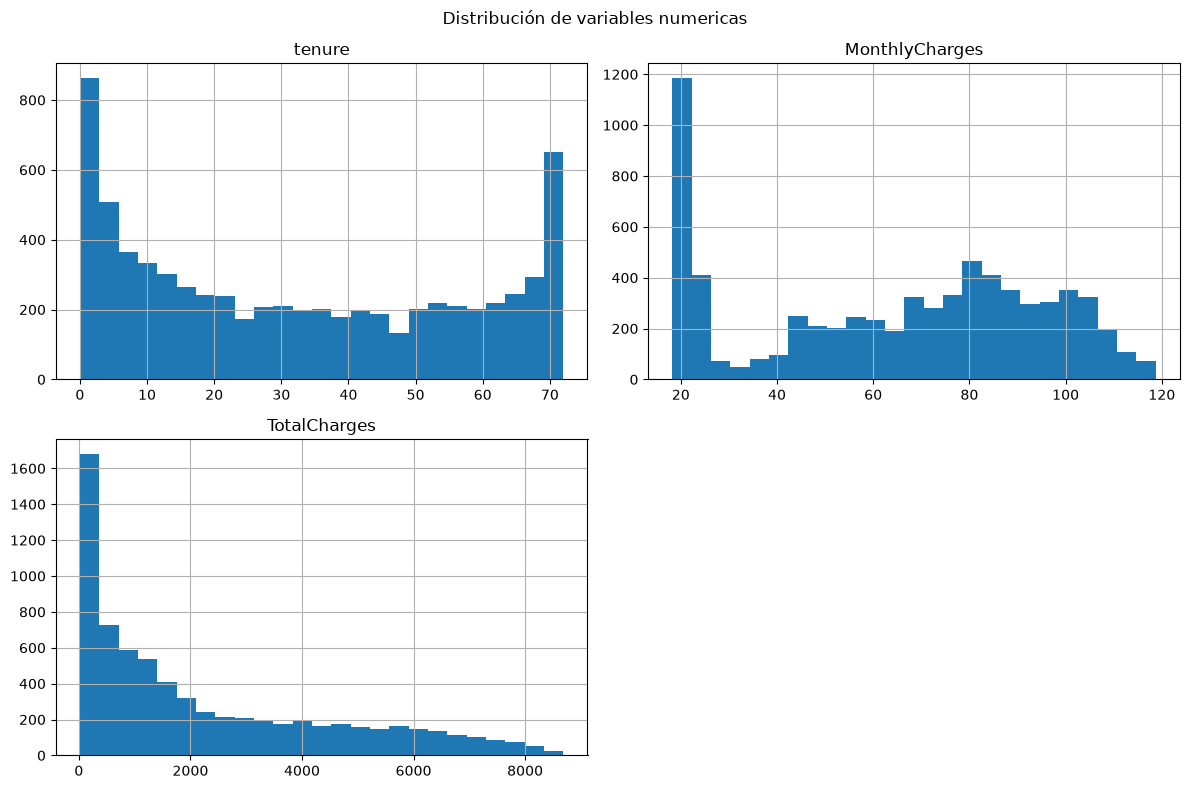

In [49]:
columnas_numericas = ["tenure", "MonthlyCharges", "TotalCharges"]

clientes_copia[columnas_numericas].hist(
    bins=25,
    figsize=(12, 8),
)

plt.suptitle("Distribución de variables numericas")
plt.tight_layout()
plt.show()

### Analisis de las variables numericas segun el abandono

He utilizado diagramas de cajas para comprobar las variables numericas del dataset entre los clientes que abandonan la empresa y los que se quedan.

**Tenure (Meses que llevan los clientes en la empresa):** Se puede ver que hay una mayor concentracion de clientes que abandonan la empresa en los primeros meses en los que etan en la empresa.

**Cargos mensuales:**  Se ve que los que se van de la emprtesa sulen pagar mas al mes con una media de 80€, mientras que los que se quedan en la empresa tienen una media de gasto al mes de unos 65€

**Cragos totales:** Se ve que los que abnadonan la empresa tiene un gasto total menos que los que se quedan, los que se quedan tienen una media de casi 2000€ mientras que los que se van mas o menos de 1000€, aunqie hay muchos outliers con un gasto muy grande

### Viendo estas variables se puede ver que el perfil que abandona la empresa son clientes que llevan poco tiempo en la empresa y que tienen un gasto mensual alto

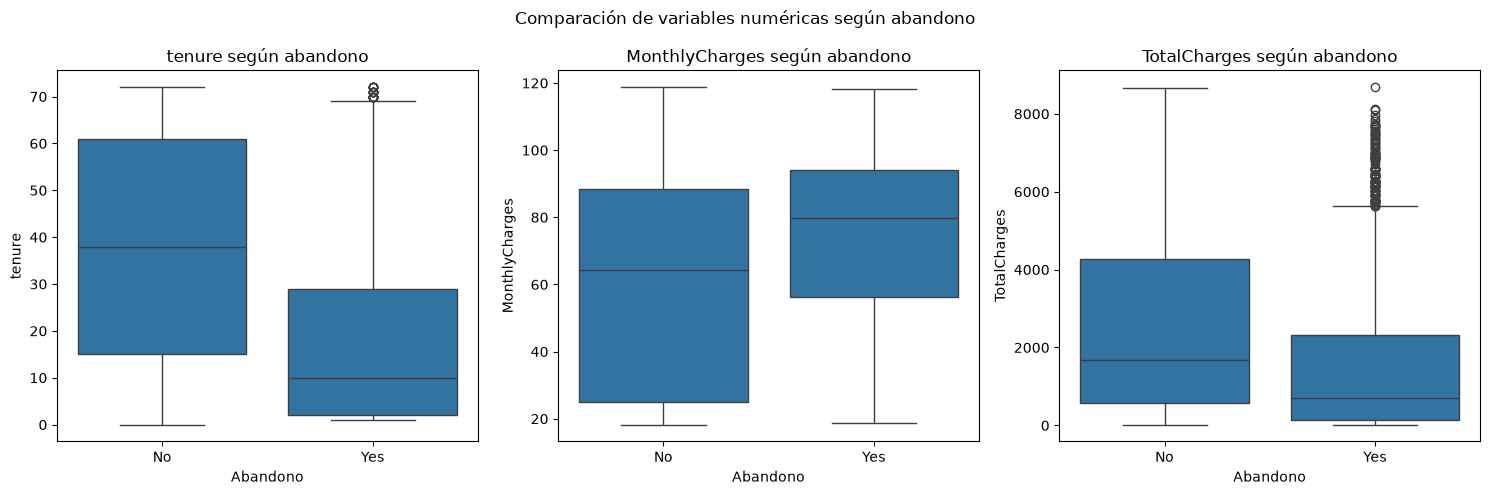

In [50]:
plt.figure(figsize=(15, 5))

for i, variable in enumerate(columnas_numericas, 1):
    plt.subplot(1, 3, i)

    sns.boxplot(
        data=clientes,
        x="Churn",
        y=variable,
        order=["No", "Yes"]
    )

    plt.title(f"{variable} según abandono")
    plt.xlabel("Abandono")
    plt.ylabel(variable)

plt.suptitle("Comparación de variables numéricas según abandono")
plt.tight_layout()
plt.show()

## Estadisticas de las columas numericas

In [51]:
clientes_copia[columnas_numericas].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


## Porcentaje en algunas variables

Para hacer los porcentajes vamos a utilizar el dataset original

In [52]:
variables = ["Contract", "InternetService", "PaymentMethod", "gender", "PaperlessBilling", "Churn"]

for variable in variables:

    print(f"\nFrecuencias de {variable}:")

    frecuencias = clientes[variable].value_counts(dropna=False)
    porcentajes = clientes[variable].value_counts(normalize=True, dropna=False) * 100

    tabla = pd.DataFrame({
        "Frecuencia": frecuencias,
        "Porcentaje (%)": porcentajes.round(2)
    })

    display(tabla)


Frecuencias de Contract:


,Frecuencia,Porcentaje (%)
Contract,,
Month-to-month,3875,55.02
Two year,1695,24.07
One year,1473,20.91



Frecuencias de InternetService:


,Frecuencia,Porcentaje (%)
InternetService,,
Fiber optic,3096,43.96
DSL,2421,34.37
No,1526,21.67



Frecuencias de PaymentMethod:


,Frecuencia,Porcentaje (%)
PaymentMethod,,
Electronic check,2365,33.58
Mailed check,1612,22.89
Bank transfer (automatic),1544,21.92
Credit card (automatic),1522,21.61


... (2 outputs left out)


Frecuencias de PaperlessBilling:


,Frecuencia,Porcentaje (%)
PaperlessBilling,,
Yes,4171,59.22
No,2872,40.78



Frecuencias de Churn:


,Frecuencia,Porcentaje (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


## Porcentajes y Analisis del abandono de la empresa a partir de diferentes variables

### Abandono a partir del contrato que tenga cada cliente

Primero vamos a ver que porcentaje total del los clientes tiene contratado cada modalidad de contrato, en este caso se ve que la mayoria de los clientes de la empresa tiene la modalidad de contrato de mes a mes(con un 55%) seguido de la modalidad de 2 años (con un 24%) y por ultimo la modalidad de 1 año (con un 21%)

,Numero de clientes,Porcentaje
Contract,,
Month-to-month,3875,55.02
One year,1473,20.91
Two year,1695,24.07


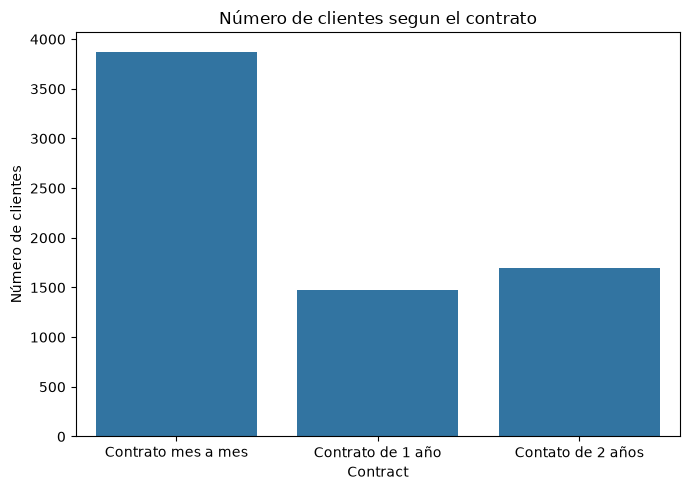

In [53]:
conteo_contrato = clientes["Contract"].value_counts().sort_index()
frecuencia_contrato = clientes["Contract"].value_counts(normalize=True).sort_index() * 100

resumen_contrato = pd.DataFrame({
    "Numero de clientes": conteo_contrato,
    "Porcentaje": frecuencia_contrato.round(2)
})

display(resumen_contrato)


plt.figure(figsize=(7, 5))
sns.countplot(data=clientes, x="Contract")
plt.xticks([0, 1, 2], ["Contrato mes a mes", "Contrato de 1 año", "Contato de 2 años"])
plt.title("Número de clientes segun el contrato")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()

In [54]:
def calcular_abandono(variable):
    return (variable == "Yes").mean() * 100

print(f"\nAbandono según el tipo de contrato del cliente:")

conteo_contrato = clientes[clientes["Churn"] == "Yes"]["Contract"].value_counts()
abandono_por_contrato = clientes.groupby("Contract")["Churn"].apply(calcular_abandono).round(2)

abandono_contrato = pd.DataFrame({
    "Numero de clientes": conteo_contrato,
    "Porcentaje": abandono_por_contrato
})

display(abandono_contrato)


Abandono según el tipo de contrato del cliente:


,Numero de clientes,Porcentaje
Contract,,
Month-to-month,1655,42.71
One year,166,11.27
Two year,48,2.83


En esta tabla se ve que el mayor porcentaje de abandono esta el la modalidad de contrato de mes a mes (con un 42,71%), que a su vez es la que mas clientes tiene en la empresa

### Abandono a partir si el cliente tiene contratado internet y de que tipo con la compañia

SE ve que la mayoria de los clientes tiene contratado internet con fibra optica (con un 44%), seguido de los clientes que lo tienen contratado con DSL (con un 34,4%) y por ultimo los clientes que no tiene contratado internet con la compañia (con un 21,7%)

,Numero de clientes,Porcentaje
InternetService,,
DSL,2421,34.37
Fiber optic,3096,43.96
No,1526,21.67


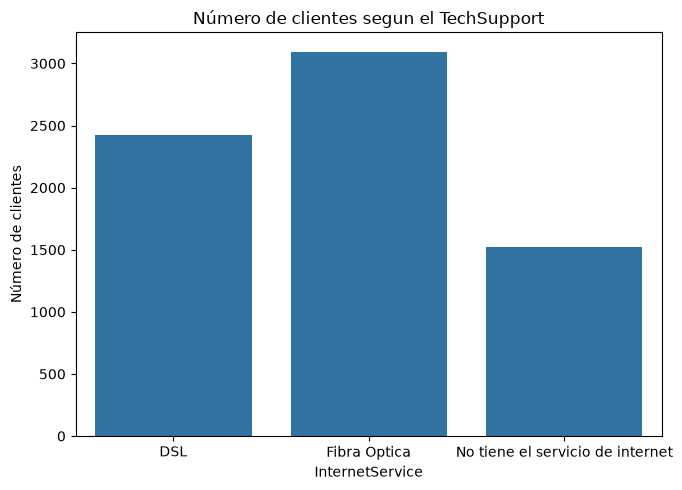

In [55]:
conteo_internet = clientes["InternetService"].value_counts().sort_index()
frecuencia_internet = clientes["InternetService"].value_counts(normalize=True).sort_index() * 100

resumen_internet = pd.DataFrame({
    "Numero de clientes": conteo_internet,
    "Porcentaje": frecuencia_internet.round(2)
})

display(resumen_internet)

plt.figure(figsize=(7, 5))
sns.countplot(data=clientes, x="InternetService")
plt.xticks([0, 1, 2], ["DSL", "Fibra Optica", "No tiene el servicio de internet"])
plt.title("Número de clientes segun el TechSupport")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()

In [56]:
print(f"\nAbandono según si tiene internet y de que tipo:")

conteo_internet = clientes[clientes["Churn"] == "Yes"]["InternetService"].value_counts()
abandono_por_internet = clientes.groupby("InternetService")["Churn"].apply(calcular_abandono).round(2)

abandono_internet = pd.DataFrame({
    "Numero de clientes": conteo_internet,
    "Porcentaje": abandono_por_internet
})

display(abandono_internet)


Abandono según si tiene internet y de que tipo:


,Numero de clientes,Porcentaje
InternetService,,
DSL,459,18.96
Fiber optic,1297,41.89
No,113,7.40


En esta tabla se ve que la mayoria de clientes que abandona la compañia son los que tienen contratado internet con la fibra optica (con un 41,9%), que a su vez es la que mas clientes tienen contratado con la empresa

### Abandono a partir si el cliente tiene contratado TechSuport

Voy a ver primero cuantos clientes tiene cada variable de TechSuport, en este caso la mayoria de clientes no tien contratado el servicio (con un 49,3%), seguido de los que si que lo tienen contratado (con un 29%) y por ultimo los que notienen el servicio de internet (con un 21,7%)

,Numero de clientes,Porcentaje
TechSupport,,
No,3473,49.31
No internet service,1526,21.67
Yes,2044,29.02


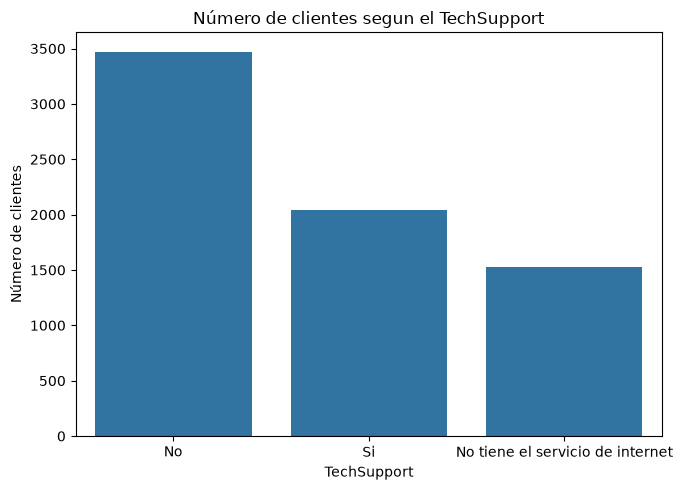

In [57]:
conteo_techSupport = clientes["TechSupport"].value_counts().sort_index()
frecuencia_techSupport = clientes["TechSupport"].value_counts(normalize=True).sort_index() * 100

resumen_techSupport = pd.DataFrame({
    "Numero de clientes": conteo_techSupport,
    "Porcentaje": frecuencia_techSupport.round(2)
})

display(resumen_techSupport)

plt.figure(figsize=(7, 5))
sns.countplot(data=clientes, x="TechSupport")
plt.xticks([0, 1, 2], ["No", "Si", "No tiene el servicio de internet"])
plt.title("Número de clientes segun el TechSupport")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()

In [58]:
print(f"\nAbandono según si tiene contratado TechSupport:")

conteo_techSupport = clientes[clientes["Churn"] == "Yes"]["TechSupport"].value_counts()
abandono_por_techSupport = clientes.groupby("TechSupport")["Churn"].apply(calcular_abandono).round(2)

abandono_techSupport = pd.DataFrame({
    "Numero de clientes": conteo_techSupport,
    "Porcentaje": abandono_por_techSupport
})

display(abandono_techSupport)


Abandono según si tiene contratado TechSupport:


,Numero de clientes,Porcentaje
TechSupport,,
No,1446,41.64
No internet service,113,7.40
Yes,310,15.17


En esta tabla se ve que la mayoria de los clientes que abandona la compañia son los que no tienen contratado TechSupport (con un 41,6%)

### Abandono de los clientes a apartir de si tienen facturación si papel o no (PaperlessBilling)

Voy a ver cuantos clientes tiene cada variable de esta categora y el procentaje de esta, en este caso la mayoria si tienen el sistema de facturacion sin papel (un 59%)

,Numero de clientes,Porcentaje
PaperlessBilling,,
No,2872,40.78
Yes,4171,59.22


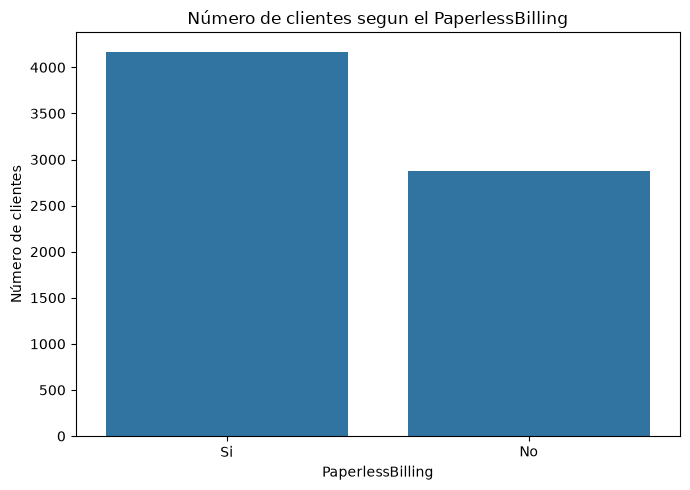

In [59]:
conteo_PaperlessBilling = clientes["PaperlessBilling"].value_counts().sort_index()
frecuencia_PaperlessBilling = clientes["PaperlessBilling"].value_counts(normalize=True).sort_index() * 100

resumen_PaperlessBilling = pd.DataFrame({
    "Numero de clientes": conteo_PaperlessBilling,
    "Porcentaje": frecuencia_PaperlessBilling.round(2)
})

display(resumen_PaperlessBilling)

plt.figure(figsize=(7, 5))
sns.countplot(data=clientes, x="PaperlessBilling")
plt.xticks([0, 1], ["Si", "No"])
plt.title("Número de clientes segun el PaperlessBilling")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()

In [60]:
print(f"\nAbandono según si tiene contratado PaperlessBilling:")

conteo_PaperlessBilling = clientes[clientes["Churn"] == "Yes"]["PaperlessBilling"].value_counts()
abandono_por_PaperlessBilling = clientes.groupby("PaperlessBilling")["Churn"].apply(calcular_abandono).round(2)

abandono_PaperlessBilling = pd.DataFrame({
    "Numero de clientes": conteo_PaperlessBilling,
    "Porcentaje": abandono_por_PaperlessBilling
})

display(abandono_PaperlessBilling)


Abandono según si tiene contratado PaperlessBilling:


,Numero de clientes,Porcentaje
PaperlessBilling,,
No,469,16.33
Yes,1400,33.57


### Abandono de los clientes a partir si tienen contratado PhoneService

,Numero de clientes,Porcentaje
PhoneService,,
No,682,9.68
Yes,6361,90.32


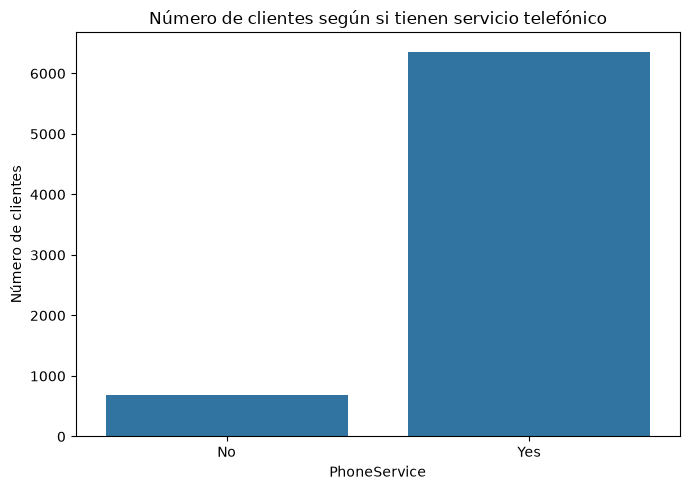

In [61]:
conteo_PhoneService = clientes["PhoneService"].value_counts().sort_index()
frecuencia_PhoneService = clientes["PhoneService"].value_counts(normalize=True).sort_index() * 100

resumen_PhoneService = pd.DataFrame({
    "Numero de clientes": conteo_PhoneService,
    "Porcentaje": frecuencia_PhoneService.round(2)
})

display(resumen_PhoneService)


plt.figure(figsize=(7, 5))
sns.countplot(data=clientes, x="PhoneService")
plt.title("Número de clientes según si tienen servicio telefónico")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()

In [62]:
print(f"\nAbandono según si tiene contratado PhoneService:")

conteo_PhoneService = clientes[clientes["Churn"] == "Yes"]["PhoneService"].value_counts()
abandono_por_PhoneService = clientes.groupby("PhoneService")["Churn"].apply(calcular_abandono).round(2)

abandono_PhoneService = pd.DataFrame({
    "Numero de clientes": conteo_PhoneService,
    "Porcentaje": abandono_por_PhoneService
})

display(abandono_PhoneService)


Abandono según si tiene contratado PhoneService:


,Numero de clientes,Porcentaje
PhoneService,,
No,170,24.93
Yes,1699,26.71


En esta tabla se ve el porcentaje de abandono depenedeiendo si tienen o no contartado en servicio de telefonia esta muy igualado (con un 25/26% de tasa de abandono en los dos casos)

### Abandono de los clientes a partir si tienen contratado varias lineas de telefono (MultipleLines)

,Numero de clientes,Porcentaje
MultipleLines,,
No,3390,48.13
No phone service,682,9.68
Yes,2971,42.18


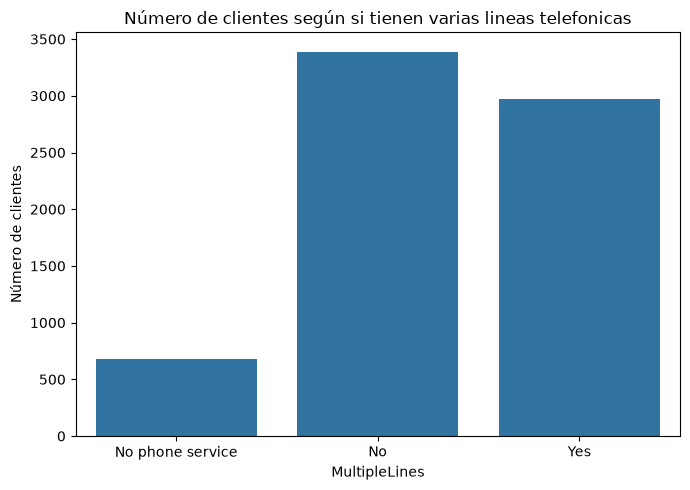

In [63]:
conteo_MultipleLines = clientes["MultipleLines"].value_counts().sort_index()
frecuencia_MultipleLines = clientes["MultipleLines"].value_counts(normalize=True).sort_index() * 100

resumen_MultipleLines = pd.DataFrame({
    "Numero de clientes": conteo_MultipleLines,
    "Porcentaje": frecuencia_MultipleLines.round(2)
})

display(resumen_MultipleLines)


plt.figure(figsize=(7, 5))
sns.countplot(data=clientes, x="MultipleLines")
plt.title("Número de clientes según si tienen varias lineas telefonicas")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()

In [64]:
print(f"\nAbandono según si tiene contratado varias lineas telefoicas (MultipeLines):")

conteo_MultipleLines = clientes[clientes["Churn"] == "Yes"]["MultipleLines"].value_counts()
abandono_por_MultipleLines = clientes.groupby("MultipleLines")["Churn"].apply(calcular_abandono).round(2)

abandono_MultipleLines = pd.DataFrame({
    "Numero de clientes": conteo_MultipleLines,
    "Porcentaje": abandono_por_MultipleLines
})

display(abandono_MultipleLines)


Abandono según si tiene contratado varias lineas telefoicas (MultipeLines):


,Numero de clientes,Porcentaje
MultipleLines,,
No,849,25.04
No phone service,170,24.93
Yes,850,28.61


### Analisis de abandono por tramo de antiguedad en la empresa

Vamos a crear varios tramos de meses de antiguedad que lleva el cliente en la empresa para poder hacer un analisis  de abandono de la empresa

In [65]:
def tipo_antiguedad(meses):
    if meses <= 6:
        return "0-6 meses"
    elif meses <= 12:
        return "7-1 año"
    elif meses <= 24:
        return "Mas de 1 año-2 años"
    elif meses < 48:
        return "Mas de 2 años-3 años"
    else:
        return "Mas de 3 años"



In [66]:
clientes_copia["Tramo_antiguedad"] = clientes_copia["tenure"].apply(tipo_antiguedad)

In [67]:
clientes_copia

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,OnlineBackup,PaperlessBilling,MonthlyCharges,TotalCharges,...,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Tramo_antiguedad
0,0,0,1,0,1,0,Yes,1,29.85,29.85,...,0,0,1,0,0,0,0,1,0,0-6 meses
1,1,0,0,0,34,1,No,0,56.95,1889.50,...,0,0,0,1,0,0,0,0,1,Mas de 2 años-3 años
2,1,0,0,0,2,1,Yes,1,53.85,108.15,...,0,0,1,0,0,0,0,0,1,0-6 meses
3,1,0,0,0,45,0,No,0,42.30,1840.75,...,0,0,0,1,0,1,0,0,0,Mas de 2 años-3 años
4,0,0,0,0,2,1,No,1,70.70,151.65,...,0,0,1,0,0,0,0,1,0,0-6 meses
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,24,1,No,1,84.80,1990.50,...,0,1,0,1,0,0,0,0,1,Mas de 1 año-2 años
7039,0,0,1,1,72,1,Yes,1,103.20,7362.90,...,0,1,0,1,0,0,1,0,0,Mas de 3 años
7040,0,0,1,1,11,0,No,1,29.60,346.45,...,0,0,1,0,0,0,0,1,0,7-1 año
7041,1,1,1,0,4,1,No,1,74.40,306.60,...,0,0,1,0,0,0,0,0,1,0-6 meses


In [68]:
conteo_abandonos = clientes_copia[
    clientes_copia["Churn"] == "Yes"
].groupby("Tramo_antiguedad", observed=False).size()


abandono_por_tramo = clientes_copia.groupby(
    "Tramo_antiguedad",
    observed=False
)["Churn"].apply(calcular_abandono).round(2)

abandono_por_tramo

Tramo_antiguedad
0-6 meses               0.0
7-1 año                 0.0
Mas de 1 año-2 años     0.0
Mas de 2 años-3 años    0.0
Mas de 3 años           0.0
Name: Churn, dtype: float64

## Matriz de Correlación

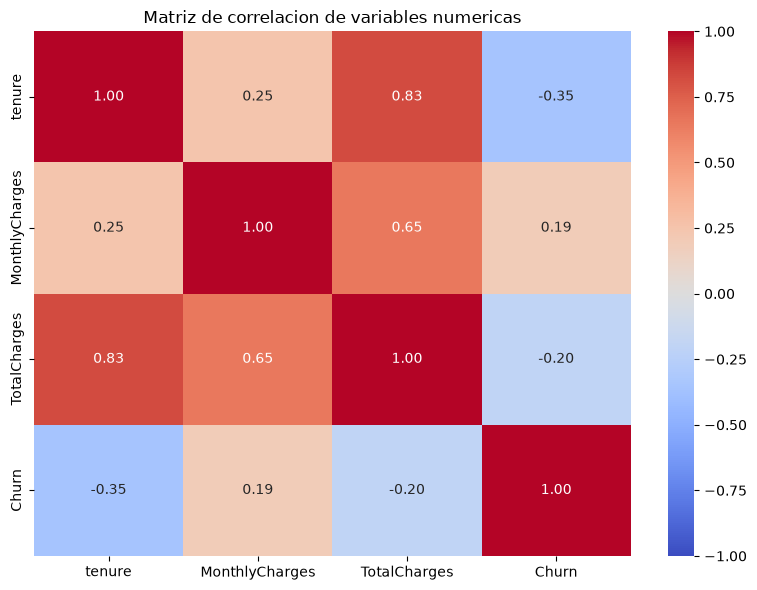

In [69]:
columnas_corr = [c for c in ["tenure", "MonthlyCharges", "TotalCharges", "Churn"] if c in clientes_copia.columns]
corr = clientes_copia[columnas_corr].astype(float).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, fmt=".2f")
plt.title("Matriz de correlacion de variables numericas")
plt.tight_layout()
plt.show()

## Matriz de Correlacion de otras variables


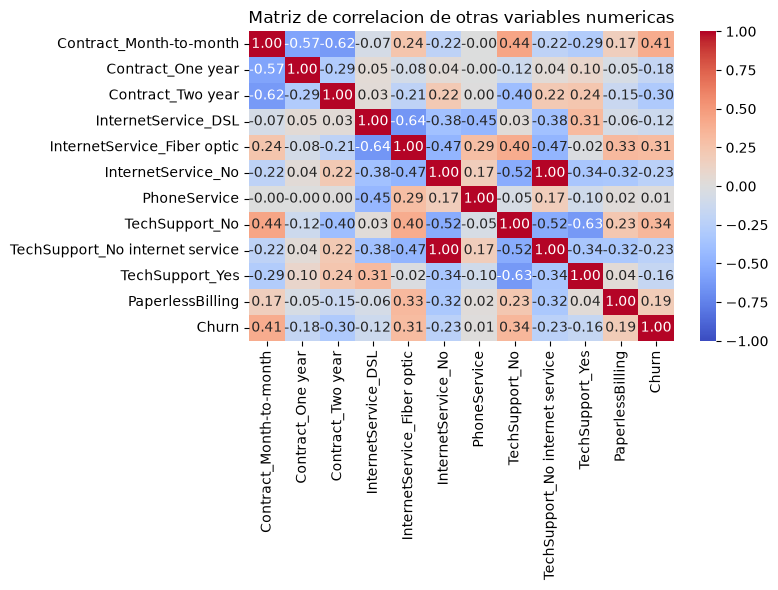

In [74]:
columnas_corr = [c for c in ["Contract_Month-to-month", "Contract_One year", "Contract_Two year", "InternetService_DSL", "InternetService_Fiber optic", "InternetService_No", "PhoneService", 'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes', "PaperlessBilling", "Churn"] if c in clientes_copia.columns]
corr = clientes_copia[columnas_corr].astype(float).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, fmt=".2f")
plt.title("Matriz de correlacion de otras variables numericas")
plt.tight_layout()

En esta matriz de  correlacion general con las que para mi son las caracteristicas mas importantes se puede ver cuales tiene mas relacion con el abando de de la empresa.

El que mas relacion tiene segun esta matriz es la modalidad de contrato de mes a mes, seguido de no tener contratado TechSupport y por ultimo tener contratado  fibra Optica en el servicio de internet